# 03 · BENCHMARKING AI TEST GENERATION

## THE SCENARIO IN PLAIN TERMS

**Harbourlight Health** is a fictional health insurer used throughout this portfolio.\
Its claims platform decides what happens to each claim a member submits: pay it, send it to a claims assessor, or recommend declining it.\
The rules are things like "a GP visit is paid up to €60", "most treatment is not covered in the first 182 days" and "a claim must be submitted within 12 months".

The earlier notebooks tested Harbourlight's AI features directly: 
- notebook 01 an AI that triages claims, 
- notebook 02 a chatbot that answers members' questions.

This notebook looks at a different use of AI, one aimed at testers themselves: **asking an AI to write the test cases.**

Teams increasingly paste a user story into an AI tool and get a list of test cases back in seconds. Two questions follow:

1. **Are those test cases any good?** Do they cover what an experienced tester would test, especially limits, dates and things that should *not* happen?
2. **Does telling the AI how to design tests help?** For example, asking it to test each side of every limit.

### HOW WE FIND OUT

It works like an exam with a marked answer key:

| In an exam | Here |
|---|---|
| The exam paper | 10 user stories for Harbourlight's claims platform, each with acceptance criteria |
| The model answer | 78 test ideas an experienced QA lead expects for those stories (the "golden set") |
| The candidate | The AI writing the test cases (`gpt-6-luna`), sitting the exam with two different sets of instructions |
| The marker | A second, stronger AI (`gpt-6-sol`) that checks each test case against the story and the model answer |
| The second marker | The QA lead, re-marking a sample to check the AI marker can be trusted |

The candidate only ever sees the exam paper, never the model answer. Each set of instructions sits the exam three times, because an AI does not give the same answer twice.

### WHAT WE COMPARE

- **Prompt v1:** "Here is a user story. Write test cases for it."
- **Prompt v2:** the same, plus seven standard test-design techniques, such as equivalence partitioning, boundary value analysis and negative testing.

Same AI, same stories, same marker, so any difference comes from the instructions.

All data is synthetic: no real insurer, policy, person or medical record is used.

## RESULTS AT A GLANCE

3 runs per prompt, mean [min–max].

| | Prompt v1 | Prompt v2 |
|---|---|---|
| Expert ideas found (recall) | 0.63 [0.60–0.64] | **0.75** [0.70–0.78] |
| Boundary ideas found | 0.49 | **0.63** |
| Cases written per run | 78 | 130 |
| Precision (correct, not duplicate) | 1.00 | 0.91 |
| Cost per run, generation + judge ($) | 0.22 | 0.32 |

- v2 finds more of the expert's ideas, and the two prompts' ranges do not overlap, so the gain is larger than run-to-run variation.
- v2 writes about 5 extra cases for every extra idea it finds, so a reviewer pays for the gain.
- Twelve ideas were never found by either prompt in any run. They are domain traps and rule interactions, which general technique guidance does not reach.
- The AI marker's verdicts on whether an idea was covered, and whether a case was correct, held up against the QA lead's blind re-marking on unseen cases (96% and 90% agreement). Its labels for test technique and concrete test data did not (50% and 65%), mainly because people apply those definitions differently.

**How to run:** restart and run all. Every step that calls a model sits behind a `RUN_* = False` switch and the notebook reads saved results otherwise, so a full run is free.

## HOW THE BENCHMARK WORKS

The diagram shows each step and the code that runs it. In exam terms: stages 1–6 set the paper and collect the candidate's answers; stages 7–12 mark them and check the marker.

![Day 4 flow](images/day4_testgen_flow.svg)

The code lives in `bench/` so this notebook and the Day 5 CI job share one implementation.

## GLOSSARY

Terms used in this notebook, in the order you meet them. Where testing has several names for one thing, they are listed together.

| Term | Meaning |
|---|---|
| **User story** | A short requirement written from a user's point of view: "As a claims assessor, I want …, so that …" |
| **Acceptance criteria (ACs)** | The numbered rules a story must meet, e.g. "AC2: An amount exactly equal to the limit is within the limit." |
| **Story card** | The story's ID, title, user story and ACs: everything the AI test writer is shown, and nothing else |
| **Test basis** | The documents tests are derived from. Here: `plan_rules.md` and the Day 3 member documents, summarised into each story's ACs. |
| **Golden set** | The frozen file `datasets/testgen_golden.json`. It holds both the exam paper (the 10 stories and their ACs, which the AI sees) and the answer key (the 78 expected test ideas, which only the judge sees). |
| **Expected test idea** | One entry in the answer key: one test an experienced tester would expect for one story, written as a condition and an outcome with exact values, e.g. S05-I03 "Treatment on 10 March 2027, submitted on 11 March 2028, is decline_recommended with LATE_SUBMISSION." |
| **Answer key** (also **model answer**, **oracle**) | All 78 expected test ideas together: what the AI's test cases are marked against. "Oracle" is the ISTQB term for the source of expected results. |
| **Prompt** | The written instructions given to the AI. v1 and v2 differ only in the test-design techniques v2 adds. |
| **Generator** (also **system under test**) | The AI writing the test cases: prompt v1 or v2 running on `gpt-6-luna` |
| **Run** | One pass of a prompt over all 10 stories. Each prompt has 3 runs because the AI's output varies. |
| **Non-determinism** | The same input giving different outputs on different runs. Results are reported as a mean and a min–max range. |
| **Judge** (also **LLM-as-a-judge**, **marker**) | A second, stronger AI (`gpt-6-sol`) that marks each test case against the story, and checks which expected ideas the cases cover |
| **Error analysis** | Reading real outputs before choosing what to measure, so the measures target the failures that actually occur |
| **Seeded defects** | Hand-made test cases with a known right answer, some deliberately flawed and some correct ("controls"), used to test the judge. The same idea as mutation testing. |
| **Calibration** | Comparing the judge's verdicts with a person's labels to see how far the judge can be trusted |
| **Blind labels** | Labels given by the QA lead without seeing the judge's verdicts, so they are independent |
| **Held-out check** | Calibration on cases neither the judge's rules nor the labeller had seen before, giving an unbiased agreement figure |
| **False pass** | The judge passing something the person would fail: a case marked correct, or an idea marked covered, when it should not be. The costly error. |
| **Positive / negative / boundary** | How a test is classified. **Positive:** valid input, a rule applies as stated (including declines). **Negative:** missing, invalid or misleading input, or a rule that must not apply. **Boundary:** a stated value on, or one smallest step from, a limit or date. |
| **Equivalence partitioning** | Grouping inputs that should behave the same way and testing one from each group |
| **Boundary value analysis** | Testing at and around a limit. **Two-value:** the limit and the first value past it (€1,500 and €1,500.01). **Three-value:** also the value just inside (€1,499.99). ISTQB describes both. |
| **Not in basis** | A test case asserting behaviour the story does not define. Not always a defect: it can be a fair question about a gap in the specification. |
| **Duplicate** | A case testing the same condition, with the same expected outcome, as an earlier case |
| **Concrete** | A case whose inputs that matter are specific (an exact amount, date or item), so a tester can run it without choosing test data |
| **Atomic** | A case testing one condition with one expected outcome, so one failure points to one cause |
| **Fingerprint** | A 12-character code computed from a file's content (SHA-256). It changes when the content changes, so every result records which golden set, prompt and judge produced it. |

## WHAT WE MEASURE, AND HOW FAR TO TRUST IT

Each measure answers one question about the AI's test cases. The last column comes from calibrating the judge (section 6): how often its verdicts agreed with the QA lead's blind labels on cases neither had seen before.

| Measure | Question it answers | How it is measured | Better is | How far to trust it |
|---|---|---|---|---|
| **Recall** | Did the AI find the tests an expert would expect? | Share of the 78 expected ideas covered by at least one case the judge marked correct; also split by technique (positive, negative, boundary) | Higher | **High:** 96% agreement, no false passes; the judge errs strict |
| **Precision** | How much of what it wrote is worth keeping? | Share of cases that are correct and not duplicates | Higher | **Moderate:** verdicts 90% agreement; duplicates slightly under-counted |
| **Precision excluding not in basis** | The same, ignoring cases that ask about gaps in the specification | As precision, leaving not-in-basis cases out | Higher | Moderate |
| **Case count** | How much is there to review? | Number of cases per run | Read with recall and precision: more cases can raise recall without being better | Exact |
| **Not in basis** | How often does it assert behaviour the story does not define? | Count of cases with that verdict | Depends: inventions are bad, specification questions can be useful | Moderate |
| **Duplicates** | How often does it repeat itself? | Count of cases the judge marks as repeating an earlier case | Lower | Moderate: 10 of 12 pairs agreed, 2 missed |
| **Schema validity** | Is the output usable at all? | Reply is valid JSON with all required fields | 10 of 10 stories | Exact (no judge involved) |
| **Claimed AC coverage** | Does the AI say every AC is covered? | Share of ACs listed in the cases' "covers" field | Read against verified coverage | Exact, but 100% in every run, so it tells us little |
| **Verified AC coverage** | Is every AC really tested? | Share of ACs with at least one correct case the judge agrees exercises it | Higher | Not checked against human labels |
| **Concrete rate** | Could a tester run the cases without inventing test data? | Share of cases the judge marks concrete | Higher | **Low:** 65% agreement; indicative only |
| **Atomic rate** | Does each case test one thing? | Share of cases the judge marks atomic | Higher | High: 90% agreement |
| **Negative and boundary presence** | Does each story get at least one negative and one boundary case? | Stories with both, using the judge's technique labels | Higher | **Low:** technique labels 50% agreement; indicative only |
| **Cost and time** | What does a run cost? | Tokens × price, and seconds, for the AI writer and the judge | Lower | Exact (judge price provisional) |

## 0. SETUP

**What this does:** imports the benchmark modules, sets the switches for paid steps, and defines the chart style. All switches are off, so nothing here costs money.

In [1]:
import json, subprocess, sys, difflib
from pathlib import Path
from statistics import mean
from collections import Counter, defaultdict

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from bench import golden, score, calibration
from bench.golden import load_golden, load_prompt, story_card

# Paid steps: switch on only to regenerate results (see each section for the cost)
RUN_GENERATE = False   # 5 generation runs, about $0.06
RUN_SCORE    = False   # judge scoring of 6 runs, about $1.60
RUN_SEEDED   = False   # judge self-test on seeded defects, about $0.07

JUDGE_FP = "ff34c1fc3ab1"            # judge v2 (frozen): all v1 vs v2 results use it
RESULTS = Path("results/testgen")
CHARTS = Path("results/charts"); CHARTS.mkdir(parents=True, exist_ok=True)

# Chart style: two categorical slots (v1 blue, v2 orange), recessive axes, ink for text
COL = {"v1": "#2a78d6", "v2": "#eb6834"}
INK, INK2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e8e7e3", "#fcfcfb"
plt.rcParams.update({"figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": GRID,
                     "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "text.color": INK,
                     "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "font.size": 10.5,
                     "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False})
pd.set_option("display.max_colwidth", 120)
print("golden", load_golden()["_fingerprint"], "| prompt v1", load_prompt("v1")[1], "| prompt v2", load_prompt("v2")[1])

# Code to improve showing tables containing cells with large strings of information
def show_full(df):
    # Full text, left-aligned and wrapped, no index column: for tables of long sentences
    with pd.option_context("display.max_colwidth", None):
        display(df.style.hide(axis="index").set_properties(**{"text-align": "left", "white-space": "normal"}))

golden 228e95aab97e | prompt v1 a71e8c54d488 | prompt v2 26bcc3fb6a1c


## 1. THE GOLDEN SET (ORACLE)

**What this shows:** the answer key is checked before it marks anything. The 10 stories trace to `plan_rules.md` and the Day 3 member documents. Each expected idea is a condition plus an outcome with exact values, written only from what the story card says, because the generator sees nothing else.

The validator checks structure (IDs, every AC has an idea, each story has a negative and a boundary idea unless exempt) and warns when an idea relies on a reason code the story never mentions.

In [2]:
print(subprocess.run([sys.executable, "datasets/validate_testgen_golden.py"], capture_output=True, text=True).stdout)

testgen_golden.json  version 1.0

story   ACs  ideas  pos  neg  bnd
S01       4      6    1    5    0
S02       4      8    4    2    2
S03       4     10    1    1    8
S04       5      7    3    2    2
S05       4      8    1    1    6
S06       3     10    1    1    8
S07       4      7    4    3    0
S08       4      9    6    2    1
S09       3      6    1    1    4
S10       4      7    5    2    0
total    39     78   27   20   31

ERRORS (0)

WARNINGS (0)

PASS



**Reading the output:** one row per story with counts by technique; `PASS` with no errors or warnings means the answer key is structurally sound. It does not prove the answers are right: before the set was frozen at v1.0, review corrected 14 expected ideas that were wrong or ambiguous and tightened two ACs.

## 2. THE SYSTEM UNDER TEST: PROMPTS V1 AND V2

**What this shows:** the difference between the configurations. Both prompts share the output contract; v2 adds a block of seven test-design techniques written from general test design, never from the expected ideas, so the comparison is not leaked.

The generator receives only the story card below. That rule is enforced in `bench/golden.py`.

In [3]:
v1, v2 = load_prompt("v1")[0].splitlines(), load_prompt("v2")[0].splitlines()
print("Lines in v2 that are not in v1:\n")
for line in difflib.ndiff(v1, v2):
    if line.startswith("+ ") and line[2:].strip():
        print(line[2:])
print("\nExample story card (S05), the generator's whole input:\n")
print(story_card(next(s for s in load_golden()["stories"] if s["story_id"] == "S05")))

Lines in v2 that are not in v1:

How to design the test cases:
1. Equivalence partitioning. For each acceptance criterion, identify the groups of inputs that should behave the same way, including invalid groups. Write at least one case per group. Where groups behave differently, keep them as separate cases.
2. Boundary value analysis. For every numeric limit, count or date, test the value on the boundary and the nearest value on each side, using the smallest meaningful step (for example one cent, one item or one day). Write each side as its own case.
3. Calendar edge cases. When dates are involved, consider month ends, year ends and leap years.
4. Negative testing. Test missing, invalid and misleading inputs, and cases where a rule must not apply.
5. Rule interactions. Where the criteria say one rule applies instead of another, or "even if", test a case where both conditions are true.
6. One condition per case. Do not repeat a case that tests the same condition with the same expected o

**Reading the output:** technique 3 (calendar edge cases) overlaps with four S05 ideas about leap days. Section 8 checks how much of v2's gain it explains.

## 3. GENERATION RUNS

**What this shows:** three runs per prompt at the provider's default temperature, so the spread between runs is part of the result. Each run is saved in full with its fingerprints and is never overwritten.

Paid step in ($) (`RUN_GENERATE`): about 0.008 per v1 run and 0.017 per v2 run.

In [4]:
if RUN_GENERATE:
    from bench import generate
    for p, runs in (("v1", ["2", "3"]), ("v2", ["1", "2", "3"])):
        for r in runs:
            generate.run(p, r)

gen_files = sorted(RESULTS.glob("gen_*.json"))
runs = []
for f in gen_files:
    m = json.loads(f.read_text(encoding="utf-8"))["meta"]
    t = m["totals"]
    runs.append({"prompt": m["prompt_version"], "run": m["run_label"], "cases": t["cases"],
                 "schema valid": f"{t['schema_valid']}/10", "output tokens": t["output_tokens"],
                 "cost $": round(score.cost_usd(m["model"], t["input_tokens"], t["output_tokens"]), 4),
                 "seconds": t["latency_s"], "golden": m["golden_fingerprint"], "prompt fp": m["prompt_fingerprint"]})
display(pd.DataFrame(runs))

,prompt,run,cases,schema valid,output tokens,cost $,seconds,golden,prompt fp
0,v1,1,75,10/10,14775,0.0078,143.0,228e95aab97e,a71e8c54d488
1,v1,2,80,10/10,15380,0.0081,170.0,228e95aab97e,a71e8c54d488
2,v1,3,80,10/10,16716,0.0088,174.2,228e95aab97e,a71e8c54d488
3,v2,1,139,10/10,34386,0.0179,309.6,228e95aab97e,26bcc3fb6a1c
4,v2,2,121,10/10,30434,0.0159,268.8,228e95aab97e,26bcc3fb6a1c
5,v2,3,130,10/10,32641,0.0170,292.0,228e95aab97e,26bcc3fb6a1c


**Reading the output:** `cases` is the volume a reviewer would face. Every run returned valid JSON for all 10 stories. v2 writes roughly twice the output tokens and takes about twice as long. The fingerprint columns confirm all six runs used the same golden set and the intended prompt.

## 4. ERROR ANALYSIS: DECIDING WHAT TO MEASURE

**What this shows:** before writing the judge, the v1 run 1's cases were reviewed next to the expected ideas (`results/testgen/review_v1_gpt-6-luna_g1.0_r1.html`). The failure modes identified shaped the judge's rules.

| # | Failure mode in v1 run 1 | Example |
|---|---|---|
| F1 | Abstract cases with no concrete test data | "A claim is submitted for a cosmetic procedure" |
| F2 | Boundaries only where the AC gives the values | S05 reuses AC1's dates; no €1,000.01 in S09 |
| F3 | No "rule must not fire" cases | Ophthalmology visit is not excluded |
| F4 | Misleading inputs missing | "Outside Ireland" but never a covered GP visit abroad |
| F5 | Several conditions in one case | One case checking four claim types |
| F6 | Rule interactions at limits missing | Day case at €1,500 (HIGH_VALUE) vs €1,500.01 (OVER_LIMIT) |
| F7 | Low volume on short stories | S09: 3 cases for 6 ideas |
| F8 | Claims every AC is covered | Claimed coverage 100% in all 10 stories |
| F9 | Technique labels differ from the expert's | S03 mostly labelled positive |

Matching rules were then agreed for the judge:
- **D1** equivalent values count (29 Feb 2024 for 29 Feb 2028) · 
- **D2** a class covers a member, except for boundary ideas · 
- **D3** a case must include the idea's distinguishing detail · 
- **D4** add a "concrete test data" check. 
    
Calibration later added an **atomic** check for F5.

## 5. THE JUDGE AND THE SEEDED CHECK

**What this shows:** the judge makes two calls per story. 
- Call A sees the story and the cases (never the expected ideas, so they cannot anchor its correctness verdict) and returns, per case: verdict, technique, concrete, atomic, AC claims supported and duplicate. 
- Call B sees the story, the expected ideas and the cases and returns, per idea: covered or not, and by which cases. 
The judge is never told which prompt wrote the cases.

Before scoring anything, the judge was tested on hand-made cases with known answers, including correct "control" cases that catch a judge that fails everything. This is defect seeding: mutation testing for the marker.

Paid step ($) (`RUN_SEEDED`): about 0.07.

In [5]:
if RUN_SEEDED:
    score.run_seeded()
rows = []
for f in sorted(RESULTS.glob("seeded_j*.json")):
    res = json.loads(f.read_text(encoding="utf-8"))["results"]
    fp = f.name.split("_")[1][1:]
    rows.append({"judge prompt": fp, "judge version": "v2" if fp == JUDGE_FP else "v1",
                 "checks": len(res), "passed": sum(r["pass"] for r in res),
                 "control checks passed": sum(r["pass"] for r in res if r["defect"].startswith("control"))})
display(pd.DataFrame(rows))

,judge prompt,judge version,checks,passed,control checks passed
0,29d3036b71d3,v1,33,33,15
1,ff34c1fc3ab1,v2,46,46,22


**Reading the output:** judge v1 passed 33/33 and judge v2 passed 46/46, including new seeds for each rule changed after calibration and a control that the looser recall rules still reject a vague case for a boundary idea. Seeded cases are deliberately clear-cut, so this shows the judge *can* recognise each kind of error, not that it agrees with an expert on messy real cases. That is the next section.

## 6. CALIBRATING THE JUDGE AGAINST BLIND HUMAN LABELS

**What this shows:** A sample was labelled (by me) without seeing the judge's verdicts: 20 cases (2 per story) and every expected idea for three stories (24 ideas). The comparison ran three times.

1. **Round 1:** Judge v1 on v1 run 1.
2. **Round 2: After fixing the disagreements from round 1.** Round 1 showed two kinds of disagreement, and each was fixed:
    - **The judge's instructions were too strict in places, so they were rewritten (judge v2).** For example, the judge did not accept "the referral meets the requirement" as meaning "not routed with MISSING_REFERRAL", and did not accept "treatment before day 182" as covering an idea about day 0. The new instructions accept outcomes that are clearly implied, let a range cover the values inside it, and judge "concrete" only on the inputs that matter for the rule being tested. A new check, "atomic", was also added.
    - **The QA lead (me) corrected seven of his own labels** where he had applied a definition differently from the written rules. For example, he had labelled a case that says "an amount greater than 120" as a boundary test, although it gives no exact value at the limit.

The judge v2 then re-marked the same 20 cases and 24 ideas. **This result is optimistic:** because the judge's instructions were changed specifically to resolve disagreements on these cases, so high agreement on the same cases was to be expected. It is like a student re-sitting questions they have already been given feedback on. Round 3 is the fair test.

3. **Round 3 (held-out): a fair test on new material.** The judge's instructions were now frozen with no more changes. The QA lead labelled a fresh sample, 20 cases and 24 ideas from prompt v2 run 1, without seeing the judge's verdicts. Neither had seen these cases before, and nothing was adjusted afterwards. "Held-out" means the material was kept back from the tuning in round 2, so the judge had no chance to be fitted to it. **This is the figure to quote** for how far the judge can be trusted.

In [6]:
rounds = {
    "Round 1 (judge v1)":  (next(RESULTS.glob("score_v1_*_r1_*_j29d3036b71d3_*.json")), "_labels_round1"),
    "Round 2 (judge v2, tuned)": (next(RESULTS.glob(f"score_v1_*_r1_*_j{JUDGE_FP}_*.json")), ""),
    "Round 3: held-out (judge v2, v2 run 1)": (next(RESULTS.glob(f"score_v2_*_r1_*_j{JUDGE_FP}_*.json")), ""),
}
table, agreements = {}, {}
for name, (path, suffix) in rounds.items():
    a = calibration.agreement(path, suffix); agreements[name] = a
    col = {k: (f"{v['agree']}/{v['labelled']}" if v["labelled"] else "not checked") for k, v in a["checks"].items()}
    col["false passes (verdict / idea)"] = f"{a['false_passes']['verdict']} / {a['false_passes']['idea covered']}"
    table[name] = col
display(pd.DataFrame(table))

,Round 1 (judge v1),"Round 2 (judge v2, tuned)","Round 3: held-out (judge v2, v2 run 1)"
verdict,19/20,20/20,18/20
technique,15/20,20/20,10/20
concrete,16/20,16/20,13/20
atomic,not checked,19/20,18/20
idea covered,17/24,24/24,23/24
false passes (verdict / idea),1 / 0,0 / 0,2 / 0


**Reading the output:** each cell is agreement between the judge and the human labels. A false pass is the costly error: the judge calls a case correct or an idea covered when the human does not.

- **Idea covered and verdict held up on unseen cases** (23/24, 18/20). These drive recall and precision, the comparison's headline measures. All recall disagreements had the judge stricter than the human, so recall is if anything understated.
- **Technique fell to 10/20 and concrete to 13/20 on unseen cases.** Six technique disagreements were valid inputs at a limit (€60, €1,500): they fit both "positive" and "boundary", and nothing says which wins. The same person labelled such cases boundary in round 1 and positive in the held-out round. These two measures are reported as indicative only.
- The two round 3 "false passes" are differences of interpretation, not clear judge errors. One of them exposed a genuine gap in the specification. S03's AC3 says what happens when the number of visits already paid **equals** the annual limit, but says nothing about when it is already **above** the limit. A v2 case tested that situation (9 GP visits already paid, against a limit of 8) and said the story defines no outcome. The judge accepted that as correct, because it is literally true; the QA lead marked it incorrect, because the business intent is clearly to decline. The fix belongs in the story: "equals or exceeds the annual limit".

In [9]:
held = agreements["Round 3: held-out (judge v2, v2 run 1)"]
#display(pd.DataFrame(held["disagreements"]).rename(columns={"you": "human"}))
show_full(pd.DataFrame(held["disagreements"]).rename(columns={"you": "human"}))

item,check,human,judge,judge_reason
L01 S01-TC02,concrete,True,False,The document's treatment date and amount are not specified.
L02 S01-TC01,concrete,True,False,"The treatment, treatment date and amount are not specified."
L03 S02-TC05,verdict,incorrect,correct,AC2 specifies the outcome for a blank number; this case checks that it does not apply when the number is populated.
L03 S02-TC05,technique,negative,boundary,AC2 specifies the outcome for a blank number; this case checks that it does not apply when the number is populated.
L04 S02-TC04,technique,positive,boundary,
L05 S03-TC08,verdict,incorrect,correct,
L05 S03-TC08,technique,negative,boundary,
L05 S03-TC08,concrete,False,True,
L06 S03-TC05,technique,boundary,positive,
L07 S04-TC04,concrete,True,False,The non-GP treatment and provider description are not specified concretely.


**Reading the output:** every held-out (Round 3) disagreement with the judge's own reason, for reading one by one rather than counting.

### DUPLICATES

The calibration sheets did not cover duplicates, yet v2's precision depends on them. Twelve pairs from v2 run 1 were labelled blind: the seven the judge flagged, mixed with five similar pairs it did not flag.

In [10]:
dup = pd.read_csv(RESULTS / "calibration" / "cal_duplicates_v2_gpt-6-luna_g1.0_r1.csv", encoding="utf-8-sig")
dup["agree"] = dup["judge_duplicate"] == dup["my_duplicate"]
display(dup[["pair_id", "story_id", "earlier_case", "later_case", "selected_as", "judge_duplicate", "my_duplicate", "agree", "my_reason"]])
print(f"agreement {dup['agree'].sum()}/{len(dup)}; judge flags confirmed "
      f"{((dup.judge_duplicate == 'y') & (dup.my_duplicate == 'y')).sum()}/{(dup.judge_duplicate == 'y').sum()}")

,pair_id,story_id,earlier_case,later_case,selected_as,judge_duplicate,my_duplicate,agree,my_reason
0,D01,S01,TC02,TC03,"control (similar, not flagged)",n,n,True,One refers to the treatment description and the later case refers to treatment date
1,D02,S06,TC13,TC14,"control (similar, not flagged)",n,y,False,The boundary is around 1500 rather than 1499.99; it will not tell us anything new about how the system behaves
2,D03,S04,TC01,TC14,judge flagged,y,y,True,Months are not used in the calculation
3,D04,S09,TC04,TC05,"control (similar, not flagged)",n,y,False,1199 and 1200 test the same logic; if it passes for 1200 it will pass for 1199
4,D05,S01,TC03,TC04,"control (similar, not flagged)",n,n,True,Separate data point; missing any piece of information needs to be flagged for subsequent handling
5,D06,S04,TC02,TC15,judge flagged,y,y,True,Logic is based on days difference; months are not considered
6,D07,S02,TC02,TC03,"control (similar, not flagged)",n,n,True,Two separate tests that validate different logic
7,D08,S01,TC01,TC09,judge flagged,y,y,True,Year end logic is not part of the test basis
8,D09,S01,TC01,TC08,judge flagged,y,y,True,Month end logic is not part of the test basis
9,D10,S04,TC02,TC17,judge flagged,y,y,True,Logic is the difference between two dates; leap years are not considered


agreement 10/12; judge flags confirmed 7/7


**Reading the output:** 
- All 7 judge flags were confirmed (no false flags), but the judge missed 2 duplicates (€1,499.99 vs €1,500; 1,199 vs 1,200), so v2's precision is slightly overstated. 
- Both misses come from v2's own instruction to test "the boundary and the nearest value on each side" (three-value boundary analysis); the reviewer applies two-value analysis, where both values sit on the same side of the limit. ISTQB describes both. 
- Five of the seven flagged duplicates came from technique 3 (month end, year end, leap day) in stories whose rules count days and do not depend on months.

## 7. RESULTS: PROMPT v1 AGAINST PROMPT v2

**What this shows:** 
- All six runs scored by the same frozen judge (v2). 
- Paid step ($) (`RUN_SCORE`) to re-score: about 0.21 per v1 run and 0.31 per v2 run.

In [11]:
if RUN_SCORE:
    for f in gen_files:
        score.save(score.score_run(f), write_history=True, rescore=False)

score_files = sorted(RESULTS.glob(f"score_*_j{JUDGE_FP}_*.json"))
scored = [json.loads(f.read_text(encoding="utf-8")) for f in score_files]

def precision_excl_nib(res):
    # Precision counting only cases the story defines: not-in-basis cases are left out of the denominator
    vals = []
    for s in res["stories"]:
        cases = s["judgement"]["cases_call"]["parsed"]["cases"]
        ids = [c["case_id"] for c in cases]
        in_basis = [c for c in cases if c["verdict"] != "not_in_basis"]
        good = [c for c in in_basis if c["verdict"] == "correct"
                and not (c["duplicate_of"] and c["duplicate_of"] in ids[:ids.index(c["case_id"])])]
        vals.append(len(good) / len(in_basis) if in_basis else None)
    vals = [v for v in vals if v is not None]
    return mean(vals)

per_run = []
for res in scored:
    s, m = res["summary"], res["gen_meta"]
    per_run.append({"prompt": m["prompt_version"], "run": m["run_label"],
        "recall": s["mean_recall"], "recall positive": s["mean_recall_positive"],
        "recall negative": s["mean_recall_negative"], "recall boundary": s["mean_recall_boundary"],
        "ideas covered /78": s["pooled_recall_ideas_covered"], "cases": s["total_n_cases"],
        "precision": s["mean_precision"], "precision excl. not in basis": round(precision_excl_nib(res), 3),
        "not in basis": s["total_not_in_basis"], "duplicates": s["total_dup_cases"],
        "concrete*": s["mean_concrete_rate"], "atomic": s["mean_atomic_rate"],
        "neg+bnd pass*": s["neg_bnd_pass"],
        "cost $": round(s["total_gen_cost_usd"] + s["total_judge_cost_usd"], 3),
        "gen seconds": s["total_gen_latency_s"]})
per_run = pd.DataFrame(per_run)

def summarise_prompt(g):
    out = {}
    for c in g.columns.drop(["prompt", "run"], errors="ignore"):
        out[c] = f"{g[c].mean():.2f} [{g[c].min():.2f}–{g[c].max():.2f}]" if g[c].dtype.kind == "f" \
                 else f"{g[c].mean():.1f} [{g[c].min()}–{g[c].max()}]"
    return pd.Series(out)

display(pd.DataFrame({p: summarise_prompt(g) for p, g in per_run.groupby("prompt")}))

,v1,v2
recall,0.63 [0.60–0.64],0.75 [0.70–0.78]
recall positive,0.55 [0.46–0.62],0.70 [0.67–0.75]
recall negative,0.40 [0.40–0.40],0.51 [0.37–0.65]
recall boundary,0.49 [0.44–0.53],0.63 [0.60–0.66]
ideas covered /78,49.0 [47–50],59.7 [56–62]
cases,78.3 [75–80],130.0 [121–139]
precision,1.00 [1.00–1.00],0.91 [0.90–0.93]
precision excl. not in basis,1.00 [1.00–1.00],0.94 [0.92–0.96]
not in basis,0.0 [0–0],5.7 [4–7]
duplicates,0.0 [0–0],7.0 [4–10]


**Reading the output:** mean of three runs with [min–max]. Columns marked * depend on judge labels that agreed poorly with the human in the held-out round, so read them as indicative.

- **Recall** rose from 0.63 to 0.75, with similar gains for positive (+0.15), boundary (+0.14) and negative (+0.11) ideas. v2's negative recall is the least stable measure (0.37–0.65).
- **Precision** fell from 1.00 to 0.91. Excluding not-in-basis cases it is 0.94, so most of the drop is those cases. Those cases are mostly v2 following instruction 7: "the ACs do not define handling for a missing date; record the system's response". That is a specification question, much like the open questions the expert recorded in the golden set, so it is arguably a benefit rather than an error.
- **Duplicates** appear only in v2, and section 6 showed the judge under-counts them.
- **Cost ($)** per run rises from about 0.22 to 0.32, almost all of it the judge reading more cases.

### RECALL BY TECHNIQUE

**What this shows:** the headline measure split by the technique tag on the expert's ideas (not the judge's labels, so the poor technique agreement in section 6 does not affect it). The dot is the mean of three runs; the line spans the lowest and highest run.

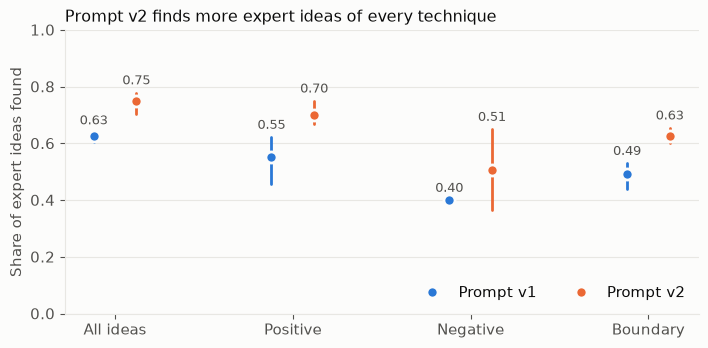

In [12]:
groups = [("recall", "All ideas"), ("recall positive", "Positive"), ("recall negative", "Negative"), ("recall boundary", "Boundary")]
fig, ax = plt.subplots(figsize=(7.2, 3.6))
for k, (col, label) in enumerate(groups):
    for off, p in ((-0.12, "v1"), (0.12, "v2")):
        v = per_run.loc[per_run.prompt == p, col]
        ax.plot([k + off, k + off], [v.min(), v.max()], color=COL[p], lw=2, solid_capstyle="round", zorder=2)
        ax.plot(k + off, v.mean(), "o", ms=8, color=COL[p], mec=SURFACE, mew=2, zorder=3,
                label=f"Prompt {p}" if k == 0 else None)
        ax.annotate(f"{v.mean():.2f}", (k + off, v.max()), xytext=(0, 6), textcoords="offset points",
                    ha="center", fontsize=9, color=INK2)
ax.set_xticks(range(len(groups)), [g[1] for g in groups])
ax.set_ylim(0, 1); ax.set_ylabel("Share of expert ideas found")
ax.set_title("Prompt v2 finds more expert ideas of every technique", loc="left", fontsize=11.5, color=INK)
ax.legend(loc="lower right", ncols=2); ax.grid(axis="x", visible=False)
fig.tight_layout(); fig.savefig(CHARTS / "testgen_recall_by_technique.png", dpi=150); plt.show()

**Reading the output:** where a prompt's line does not overlap the other's, the difference is larger than run-to-run variation. That holds for all ideas, positive and boundary. For negative ideas v2's range is wide and touches v1's, so the negative gain is not established by three runs.

### RECALL PER STORY

**What this shows:** where v2's gain comes from. Each row is one story: mean recall over three runs for v1 and v2, sorted by the gain.

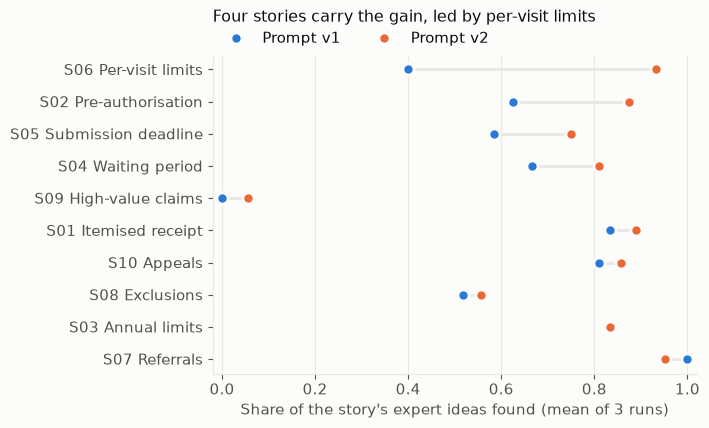

,story,title,v1,v2,gain
0,S07,Require referrals for consultant visits and physiotherapy,1.00,0.95,-0.05
1,S03,Track annual limits per policy year,0.83,0.83,0.00
2,S08,Decline excluded treatment,0.52,0.56,0.04
3,S10,Appeal a declined claim,0.81,0.86,0.05
4,S01,Submit a claim with an itemised receipt,0.83,0.89,0.06
5,S09,Flag high-value claims for review,0.00,0.06,0.06
6,S04,Apply the waiting period and its exemptions,0.67,0.81,0.14
7,S05,Enforce the claim submission deadline,0.58,0.75,0.17
8,S02,Check pre-authorisation for hospital treatment,0.62,0.88,0.25
9,S06,Check per-visit and per-item limits,0.40,0.93,0.53


In [13]:
rec = defaultdict(lambda: defaultdict(list))
for res in scored:
    for s in res["stories"]:
        rec[s["metrics"]["story_id"]][res["gen_meta"]["prompt_version"]].append(s["metrics"]["recall"])
titles = {s["story_id"]: s["title"] for s in load_golden()["stories"]}
short = {"S01": "Itemised receipt", "S02": "Pre-authorisation", "S03": "Annual limits", "S04": "Waiting period",
         "S05": "Submission deadline", "S06": "Per-visit limits", "S07": "Referrals", "S08": "Exclusions",
         "S09": "High-value claims", "S10": "Appeals"}
story = pd.DataFrame([{"story": sid, "title": titles[sid], "v1": mean(v["v1"]), "v2": mean(v["v2"])} for sid, v in rec.items()])
story["gain"] = story.v2 - story.v1
story = story.sort_values("gain").reset_index(drop=True)

fig, ax = plt.subplots(figsize=(7.2, 4.4))
for i, r in story.iterrows():
    ax.plot([r.v1, r.v2], [i, i], color=GRID, lw=2, zorder=1)
    ax.plot(r.v1, i, "o", ms=8, color=COL["v1"], mec=SURFACE, mew=2, zorder=3, label="Prompt v1" if i == 0 else None)
    ax.plot(r.v2, i, "o", ms=8, color=COL["v2"], mec=SURFACE, mew=2, zorder=3, label="Prompt v2" if i == 0 else None)
ax.set_yticks(range(len(story)), [f"{r.story} {short[r.story]}" for r in story.itertuples()])
ax.set_xlim(-0.02, 1.02); ax.set_xlabel("Share of the story's expert ideas found (mean of 3 runs)")
ax.set_title("Four stories carry the gain, led by per-visit limits", loc="left", fontsize=11.5, color=INK, pad=24)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncols=2, borderaxespad=0.2); ax.grid(axis="y", visible=False)
fig.tight_layout(); fig.savefig(CHARTS / "testgen_recall_by_story.png", dpi=150); plt.show()
display(story.round(2))

**Reading the output:** 
- Where the two dots coincide (S03, 0.83 for both) only the orange one shows. 
- S06 (per-visit limits) moved most, from 0.40 to 0.93: the boundary-value instruction made v2 write explicit values such as €60.01. 
- S09 (high-value claims) stays near zero for both prompts: neither picks a category and an exact amount, which every S09 idea needs. 
- S02 (pre-authorisation), S05 (deadline) and S04 (waiting period) also gained 0.14 or more. 
- S07 is slightly lower for v2 (0.95 against 1.00).

### WHAT THE EXTRA RECALL COSTS IN REVIEW EFFORT

**What this shows:** each dot is one run. Moving right means more cases for a reviewer to read; moving up means more expert ideas found.

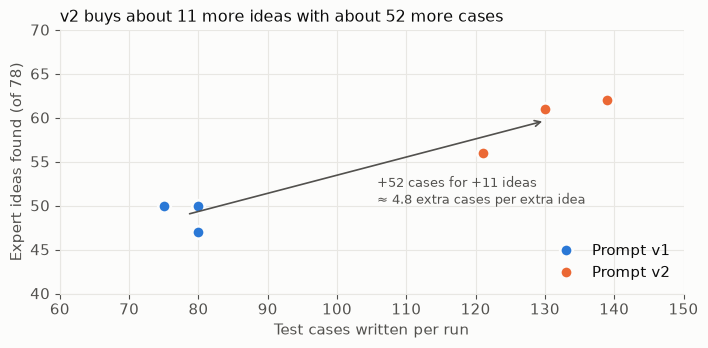

In [14]:
fig, ax = plt.subplots(figsize=(7.2, 3.6))
for p in ("v1", "v2"):
    d = per_run[per_run.prompt == p]
    ax.plot(d["cases"], d["ideas covered /78"], "o", ms=9, color=COL[p], mec=SURFACE, mew=2, label=f"Prompt {p}")
m1, m2 = per_run.groupby("prompt")[["cases", "ideas covered /78"]].mean().values
ax.annotate("", xy=m2, xytext=m1, arrowprops=dict(arrowstyle="->", color=INK2, lw=1.2))
ratio = (m2[0] - m1[0]) / (m2[1] - m1[1])
ax.annotate(f"+{m2[0]-m1[0]:.0f} cases for +{m2[1]-m1[1]:.0f} ideas\n≈ {ratio:.1f} extra cases per extra idea",
            ((m1[0] + m2[0]) / 2, (m1[1] + m2[1]) / 2), xytext=(8, -26), textcoords="offset points", fontsize=9.5, color=INK2)
ax.set_xlabel("Test cases written per run"); ax.set_ylabel("Expert ideas found (of 78)")
ax.set_xlim(60, 150); ax.set_ylim(40, 70)
ax.set_title("v2 buys about 11 more ideas with about 52 more cases", loc="left", fontsize=11.5, color=INK)
ax.legend(loc="lower right")
fig.tight_layout(); fig.savefig(CHARTS / "testgen_volume_vs_ideas.png", dpi=150); plt.show()

**Reading the output:** 
- v1 is efficient (about 0.6 expert ideas per case) but misses a third of the ideas. 
- v2 finds more at about 0.46 ideas per case. 
    
Whether roughly five extra cases per extra idea is worth it depends on how the cases are used: as a reviewed suite, every case costs review time; as a source of ideas for a tester, the extra coverage is cheap.

## 8. WHAT NEITHER PROMPT FOUND, AND THE TECHNIQUE 3 OVERLAP

**What this shows:** the ideas no run of either prompt covered, and the per-idea record for S05, where v2's calendar technique overlaps with the expected ideas.

In [16]:
gold = load_golden()
ideas = {i["idea_id"]: (s["story_id"], i["technique"], i["idea"]) for s in gold["stories"] for i in s["expected_ideas"]}
cov = {"v1": Counter(), "v2": Counter()}
for res in scored:
    for s in res["stories"]:
        cov[res["gen_meta"]["prompt_version"]].update(s["metrics"]["covered_ideas"])
never = [(i, *ideas[i]) for i in ideas if cov["v1"][i] == 0 and cov["v2"][i] == 0]
#display(pd.DataFrame(never, columns=["idea", "story", "technique", "expected idea"]))
show_full(pd.DataFrame(never, columns=["idea", "story", "technique", "expected idea"]))
s05 = pd.DataFrame([{"idea": i, "technique": ideas[i][1], "v1 runs covering (of 3)": cov["v1"][i],
                     "v2 runs covering (of 3)": cov["v2"][i], "expected idea": ideas[i][2]} for i in ideas if i.startswith("S05")])
#display(s05)
show_full(s05)

idea,story,technique,expected idea
S02-I08,S02,boundary,A hospital treatment claim with no overnight stay including a pre-authorisation number should not be routed as INPATIENT_REVIEW.
S03-I10,S03,negative,Build up 8 GP paid claims and then submit a physiotherapy claim (that is within limits) to ensure that categories do not impact each other. Routing reason codes will not be ANNUAL_LIMIT_REACHED.
S04-I06,S04,negative,"A claim for Orthopaedic consultant review based on provider description of 'Wrist fracture following a fall' is made on day 100 but there is no GP referral, so it is not routed with WAITING_PERIOD and is not auto_approve."
S05-I01,S05,positive,"Treatment on 10 March 2027, submitted on 15 June 2027 (well within 12 months), is not routed with LATE_SUBMISSION."
S08-I04,S08,negative,"A pilates class at a physiotherapy clinic, described as therapeutic, is routed to decline_recommended with reason code EXCLUDED."
S08-I08,S08,boundary,A Consultant ophthalmology visit with all correct information including referral will not be routed with reason code EXCLUDED.
S09-I01,S09,boundary,A valid day case procedure claim is submitted for €1000 so it is within the high-value limit and therefore routed but not with reason code HIGH_VALUE.
S09-I03,S09,boundary,Check that a GP visit claim above the category limit - €1000.01 - will be routed for manual_review with reason code OVER_LIMIT and not a reason code of HIGH_VALUE.
S09-I04,S09,positive,Check that a day case procedure claim of €1500 and with all other correct details (include pre-authorisation attachment) will be routed for manual_review with reason code HIGH_VALUE.
S09-I05,S09,boundary,Check that a day case procedure claim of €1500.01 and with all other correct details (include pre-authorisation attachment) will be routed for manual_review with reason code OVER_LIMIT and not HIGH_VALUE.


idea,technique,v1 runs covering (of 3),v2 runs covering (of 3),expected idea
S05-I01,positive,0,0,"Treatment on 10 March 2027, submitted on 15 June 2027 (well within 12 months), is not routed with LATE_SUBMISSION."
S05-I02,boundary,3,3,"Treatment on 10 March 2027, submitted on 10 March 2028 (the last day), is on time and is not routed with LATE_SUBMISSION."
S05-I03,boundary,3,3,"Treatment on 10 March 2027, submitted on 11 March 2028 (one day after the last day), is decline_recommended with LATE_SUBMISSION."
S05-I04,boundary,3,3,"Treatment on 29 February 2028, submitted on 28 February 2029, is on time and is not routed with LATE_SUBMISSION."
S05-I05,boundary,3,3,"Treatment on 29 February 2028, submitted on 1 March 2029, is decline_recommended with LATE_SUBMISSION."
S05-I06,boundary,2,3,"Treatment on 1 March 2027, submitted on 1 March 2028 (366 days later, across 29 February 2028), is on time and is not routed with LATE_SUBMISSION."
S05-I07,boundary,0,1,"Treatment on 28 February 2027, submitted on 29 February 2028, is decline_recommended with LATE_SUBMISSION (the last day is 28 February 2028)."
S05-I08,negative,0,2,"A claim submitted on 10 March 2028 for treatment on 10 March 2027, but processed on 20 March 2028, is judged on the submission date and is not routed with LATE_SUBMISSION."


**Reading the output:**

- **Never found (12 ideas):** five are S09's, and the rest are domain traps or rule interactions. Examples are an ophthalmology visit that is *not* excluded, a Pilates class described as therapeutic, categories not affecting each other's annual limits, the accident exemption still needing a referral, and a service complaint labelled as an appeal. General test-design guidance does not reach them. A team would need domain-specific prompts or keep a human on these.
- **Technique 3 overlap:** v2 found S05-I07 (28 Feb 2027 → 29 Feb 2028) in one run of three, and v1 already found S05-I06 (366 days) in two. S05's gain came mainly from S05-I08 (processing date vs submission date), which is the negative-testing instruction. The overlap explains little of the result, and section 6 showed the same technique produced most of v2's duplicates.
- **S05-I01** ("well within 12 months") was never covered, although both prompts write on-time cases one day before the deadline. That may be the judge being strict about which partition a value belongs to.

## 9. HOW MUCH THE MARKER'S RULES MOVE THE SCORE

**What this shows:** the same v1 run 1 cases, scored by judge v1 and by judge v2. Nothing about the generator changed.

In [17]:
pairs = {"judge v1": next(RESULTS.glob("score_v1_*_r1_*_j29d3036b71d3_*.json")),
         "judge v2": next(RESULTS.glob(f"score_v1_*_r1_*_j{JUDGE_FP}_*.json"))}
rows = {}
for name, p in pairs.items():
    s = json.loads(p.read_text(encoding="utf-8"))["summary"]
    rows[name] = {"mean recall": s["mean_recall"], "recall boundary": s["mean_recall_boundary"],
                  "mean concrete": s["mean_concrete_rate"], "neg+bnd pass (of 10)": s["neg_bnd_pass"]}
display(pd.DataFrame(rows))

,judge v1,judge v2
mean recall,0.522,0.638
recall boundary,0.399,0.440
mean concrete,0.428,0.571
neg+bnd pass (of 10),4.000,3.000


**Reading the output:** the test cases did not change; only the judge's marking instructions did. After round 1 of calibration, the instructions were made less literal: an outcome that is clearly implied now counts ("the referral meets the requirement" means "not routed with MISSING_REFERRAL"), a range covers the values inside it ("before day 182" covers day 0), background assumptions such as "all other details are correct" no longer need restating, and "concrete" is judged only on the inputs that matter for the rule being tested. That alone moved v1's recall from 0.52 to 0.64, about the same size as the difference between prompt v1 and v2 (+0.12). A score is only meaningful with the judge version beside it, which is why every result and history row records the judge's fingerprint.

## 10. THE HISTORY FILE

**What this shows:** one row per story per scored run, with every fingerprint. Day 5's scheduled CI run appends to it, so trends can be read over time and any change of golden set, prompt or judge is visible.

In [18]:
hist = pd.read_csv("results/testgen_history.csv")
display(hist.groupby(["prompt_version", "judge_cases_fp"]).agg(rows=("story_id", "size"), runs=("gen_file", "nunique"),
                                                            mean_recall=("recall", "mean")).round(3))

rows  runs  mean_recall
prompt_version judge_cases_fp                         
v1             29d3036b71d3      10     1        0.522
               ff34c1fc3ab1      30     3        0.627
v2             ff34c1fc3ab1      30     3        0.751

**Reading the output:** run 1 of v1 appears under both judge versions; comparisons only use rows with the same judge fingerprint.

## 11. LIMITATIONS

- **Small sample:** 10 stories, 3 runs per prompt, one model. Enough to show the method and a clear recall difference; not enough to generalise to other models or domains.
- **The judge was tuned on its calibration set.** Round 2's agreement is optimistic; the held-out round is the figure to quote, and it covers one run.
- **Technique and concrete labels are unreliable as measures** (50% and 65% held-out agreement), so negative/boundary presence and concrete rate are indicative.
- **Duplicates are under-counted**, so v2's precision is slightly overstated.
- **Recall is measured against a sample of ideas.** Where an AC lists equivalent items, the golden set samples one or two (equivalence partitioning). For an LLM that assumption is weaker than for code: handling acupuncture correctly does not guarantee homeopathy.
- **Story-level scope.** The generator saw one story at a time, so rule interactions across stories were not measured. A "story plus full rules" configuration would need an extended oracle.
- **Not measured:** whether the steps are executable. Most cases say "Assess the claim".
- **Cost figures** use `gpt-6.1-sol` prices for the `gpt-6-sol` judge, unconfirmed.

## 12. WHAT I LEARNED

**The finding.** Adding general test-design guidance to the prompt raised the share of expert test ideas found from 0.63 to 0.75, with gains for positive, negative and boundary ideas alike; the biggest single story gain was on per-visit limits (0.40 to 0.93). It also wrote 66% more cases, about five per extra idea found, so the gain is paid for in review time. The ideas neither prompt found were domain traps and rule interactions, the cases an experienced tester adds from knowing the business.

**The pitfalls.**
1. **The oracle is the expensive part, and it needs testing too.** Writing and reviewing 78 expected ideas took longer than everything else, and the first two review rounds alone corrected 14 expected ideas that were wrong or ambiguous and tightened two acceptance criteria. A benchmark against the first draft would have marked correct cases as failures.
2. **How you mark matters as much as what you mark.** Re-marking the same v1 test cases with clarified judge instructions moved recall from 0.52 to 0.64, the same +0.12 as the improvement from prompt v1 to v2. If the judge had been changed between the two prompts' runs, the whole gain could have come from the marker. So the judge was frozen before the comparison runs, and every score records the judge version that produced it.
3. **People disagree on definitions.** Whether a valid input at a limit is "positive" or "boundary", or whether €1,499.99 next to €1,500 is a duplicate, depends on the convention (three-value or two-value boundary analysis). Different people can apply the same definitions differently. A benchmark's definitions have to be written down and shared with every reviewer, and measures that rest on them should be treated as indicative.
4. **A judge always looks better on the cases it was tuned on.** After round 1, the judge's instructions were changed (and seven labels corrected) to resolve the disagreements on 20 cases. Re-marking those same 20 cases, technique agreement rose from 75% to 100%. On 20 new cases it fell to 50%. Only agreement on cases kept out of the tuning, the held-out round, shows how far a judge can be trusted. (Part of the fall is also the definitions problem in point 3.)
5. **"Not in basis" is not always a defect.** Most of v2's were questions about gaps in the specification, and one exposed a real gap (an annual-limit AC that only says "equals").

**What I would do in a real team.**
- Start with error analysis on real outputs before choosing metrics, and calibrate any LLM judge on blind labels plus a held-out set before trusting its numbers.
- Report recall, precision and case count together, with the judge and prompt versions beside every figure.
- Treat AI-generated tests as a source of ideas for a reviewer, not a finished suite, and keep a human involved on domain traps and rule interactions.
- Track artefacts by content fingerprint, not by name or ID, so a changed story or prompt is visible in every result.

## APPENDIX: HOW THE CODE FITS TOGETHER

The benchmark code lives in the `bench/` Python package, not in this notebook. The notebook imports it to read and present the saved results; the same modules are run from the command line (`python -m bench.<module>`) to generate the test cases, score them and build the label sheets. Each module does one job, so the system under test, the judge and the free checks can be changed and tested separately.

![How the Day 4 code fits together](images/day4_code_map.png)

| File | What it does | Calls an LLM? | Used in |
|---|---|---|---|
| `datasets/testgen_golden.json` | The 10 user stories with their acceptance criteria, and the 78 expected test ideas: the oracle. v1.0, frozen | No | Section 1 |
| `datasets/testgen_golden.schema.json` | The rules the golden set's structure must follow | No | Section 1 |
| `datasets/validate_testgen_golden.py` | Checks the golden set before any run: structure, duplicate IDs, every idea linked to a real AC, every story with a negative and a boundary idea (unless exempt), outcomes the story's own ACs can support | No | Section 1 |
| `datasets/testgen_seeded_defects.json` | 28 deliberately flawed or deliberately correct items (46 checks) for testing the judge | No | Section 5 |
| `bench/golden.py` | Loads the golden set and the prompts; `story_card()` builds what the generator may see (title, story, ACs only, so the expected ideas cannot leak); computes the fingerprints | No | Every section |
| `bench/prompts/` | Generator prompts `testgen_v1` and `testgen_v2`; judge prompts `judge_cases` and `judge_recall`, versions 1 and 2 | No (text only) | Sections 2 and 5 |
| `bench/generate.py` | **The system under test:** sends each story card with prompt v1 or v2 to `gpt-6-luna` and saves the replies, timings, tokens and fingerprints to `results/testgen/gen_*.json` | Yes: the generator | Section 3 |
| `bench/testcase_schema.py` | Recovers the JSON from each reply and checks it against the output format: required fields, valid technique, `covers` naming the story's own AC IDs | No | Section 3 |
| `bench/judge.py` | **The judge:** two calls per story to `gpt-6-sol`. Call 1 marks each case (verdict, technique, concrete, atomic, duplicate) without seeing the expected ideas; call 2 decides which expected ideas are covered, and by which cases | Yes: the judge | Sections 5 to 9 |
| `bench/score.py` | Works out the measures for a run (free ones such as case count and schema validity, then recall, precision and coverage from the judge's verdicts); runs the judge self-test on the seeded defects; writes `score_*.json` and appends to the history file | Through `judge.py` | Sections 5, 7, 9 and 10 |
| `bench/calibration.py` | Builds the blind label sheets (20 cases and 24 ideas, chosen with a fixed random seed) and measures agreement between the judge and the human labels | No | Section 6 |
| `bench/review_sheet.py` | Writes an HTML sheet of a run's cases, story by story, for reading during error analysis and labelling. It shows no judge verdicts, so labels stay blind | No | Sections 4 and 6 |
| `bench/pricing.py` | Model prices (USD per million tokens) for the cost columns; the `gpt-6-sol` price is marked provisional | No | Sections 3 and 7 |
| `03_testgen_benchmark.ipynb` | This notebook: reads the saved results, builds the tables and charts and explains them. Generation, scoring and the seeded check run only if their `RUN_*` switch is set to `True` | Only with a switch on | |
| `results/testgen/` | Generated cases (`gen_*`), scores (`score_*`), seeded checks (`seeded_*`), review sheets and `calibration/` label sheets. Each file name gives the prompt, golden-set version, run and, for scores, the judge prompt's fingerprint | No | |
| `results/testgen_history.csv` | One row per scored run with its fingerprints, measures, cost and time: the record that makes runs comparable | No | Section 10 |

**Reading the table:** only `generate.py` and `judge.py` call the OpenAI API, and both read the key from `.env`. Everything else is free and deterministic, so the checks on the oracle, the output format and the agreement figures can be re-run at no cost.